## Monte Carlo data viz

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

### load data

In [2]:
import json
import numpy as np
import os

data_path = "data/20260823/proximal_promoter_tranc_d_50_c_sweep_h0_-1.5_chi_-2.5_run{}"
n_conc = 28
_runs = range(1, 8)

keys = [
    "on_times", "off_times", "bound_times", "unbound_times",
    "pattern_distances", "transcription_activity", "binding_activity",
    "local_concentration",
]

loaded = {k: [[] for _ in range(n_conc)] for k in keys}
concentrations = [None] * n_conc

for i in range(n_conc):
    conc_id = i + 1  # keya, 1-indexed to match sim/sweep.jl
    for r in _runs:
        path = os.path.join(data_path.format(r), f"output_cpu{conc_id}.json")

        with open(path) as f:
            res_ = json.load(f)

        res = res_[str(conc_id)]["1"]
        for k in keys:
            loaded[k][i].append(np.array(res[k]))  # run_index = r - 1
        concentrations[i] = res.get("tf_concentration")

on_times = loaded["on_times"]
off_times = loaded["off_times"]
bound_times = loaded["bound_times"]
unbound_times = loaded["unbound_times"]
pattern_distances = loaded["pattern_distances"]
transcription_activity = loaded["transcription_activity"]
binding_activity = loaded["binding_activity"]
local_concentration = loaded["local_concentration"]

print(f"Loaded {n_conc} concentrations ({len(on_times[0])} runs each).")
print("concentrations:", concentrations)

Loaded 28 concentrations (7 runs each).
concentrations: [5e-05, 7.777777777777778e-05, 0.00010555555555555555, 0.00013333333333333334, 0.0001611111111111111, 0.00018888888888888888, 0.00021666666666666666, 0.00024444444444444443, 0.0002722222222222222, 0.0003, 0.0003277777777777778, 0.00035555555555555557, 0.00038333333333333334, 0.0004111111111111111, 0.0004388888888888889, 0.00046666666666666666, 0.0004944444444444445, 0.0005222222222222222, 0.00055, 0.0005777777777777778, 0.0006055555555555556, 0.0006333333333333333, 0.0006611111111111111, 0.0006888888888888888, 0.0007166666666666667, 0.0007444444444444445, 0.0007722222222222222, 0.0008]


#### Pattern distance histogram

Text(0.5, 1.0, 'TF concentration 0.0002722222222222222')

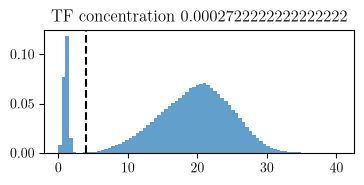

In [334]:
fig, ax = plt.subplots(1,1,figsize=(4,1.6))

k = 8
_=ax.hist(np.concatenate(pattern_distances[k]), bins=80, density=True, alpha=0.7)
# ax.set_xlim(0, 1)
xs = np.linspace(0, 50, 200)
s = 60
a = 2.0
dist = xs**2 * np.exp(-3*xs**2/(2*s*a**2))
dist = dist / np.trapezoid(dist, xs)
# ax.plot(xs, dist)
ax.axvline(4, color="black", linestyle="dashed")
ax.set_title("TF concentration {}".format(concentrations[k]))

In [ ]:
out_dir = "media/figures/20260403"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "distance_histograms.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260403/distance_histograms.pdf


#### Bound/unbound times with hysteresis

In [26]:
import viz_util.hysteresis_times
from viz_util.hysteresis_times import compute_hysteresis_times

# Recompute using hysteresis thresholds
unbound_times, bound_times = compute_hysteresis_times(
            pattern_distances, d_o=4, d_x=4.0, nparams=16, nruns=16)


IndexError: list index out of range

#### ON/OFF time empirical CDFs

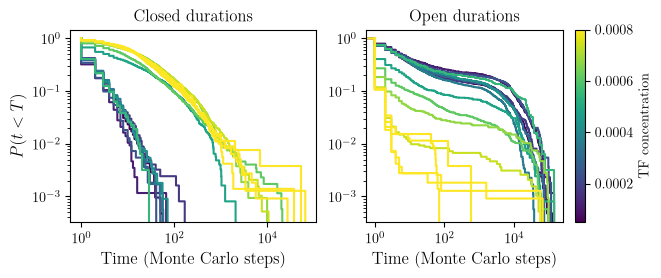

In [233]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,2, figsize=(7,2.5))

gradient = np.linspace(5e-5, 8e-4, 26)
# gradient = np.linspace(0.003, 0.014, 12)
labels = [str(l) for l in gradient]
count = 0
idxs_valid = []

for k in range(26):
    # ton_sorted = np.sort(np.concatenate(on_times[k]))
    # toff_sorted = np.sort(np.concatenate(off_times[k]))
    
    ton_sorted = np.sort(np.concatenate(bound_times[k]))
    toff_sorted = np.sort(np.concatenate(unbound_times[k]))

    if min(len(ton_sorted), len(toff_sorted)) >= 200:
        count += 1
        idxs_valid.append(k)
        ccdf_on = 1.0 - np.arange(1, len(ton_sorted) + 1) / len(ton_sorted)
        ccdf_off = 1.0 - np.arange(1, len(toff_sorted) + 1) / len(toff_sorted)

        ax[0].step(ton_sorted, ccdf_on, where='post', 
                color=plt.cm.viridis(k/12))
        ax[1].step(toff_sorted, ccdf_off, where='post', 
                color=plt.cm.viridis(k/12))
    
norm = plt.Normalize(vmin=5e-5, vmax=8e-4)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
cbar = plt.colorbar(sm, ax=ax[1], label='TF concentration')

alpha = 0.5
# ax.plot(xs_, alpha*xs_**(-alpha)*2, color="orange", linestyle="dashed",
#         label=r"$C'\alpha x^{-\alpha}, \quad \alpha=1.5$")

xs_ = np.logspace(0, 3.2, 100)
# ax[1].plot(xs_, np.exp(-(xs_)*0.0027)*xs_**-0.07, color="red")

xs_ = np.logspace(0, 4.5, 100)
# ax[0].plot(xs_, 0.055*np.exp(-(xs_)*0.00016) + np.exp(-(xs_)*0.12), color="red")

# ax[0].set_xlim(-500, 20000)
# ax[1].set_xlim(0.8, 8e4)
# ax[1].set_ylim(1e-4, 1.5)
ax[0].set_ylabel("$P(t < T)$", fontsize=12)
ax[0].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[1].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[0].set_title("Closed durations")
ax[1].set_title("Open durations")
# ax[0].set_title("ON times")
# ax[1].set_title("OFF times")

ax[0].set_yscale('log')
ax[0].set_xscale('log')

ax[1].set_yscale('log')
ax[1].set_xscale('log')

#### ON/OFF time smoothed PDFs

0.00035000000000000005 91.4373831775701 739.7378731343283


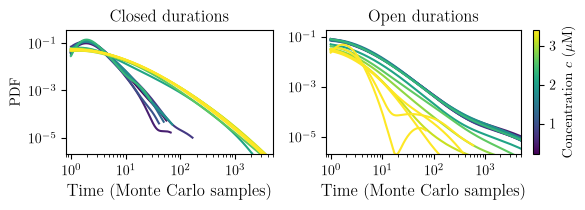

In [315]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on the log-time grid
smooth_sigma = 30       # smoothing width in grid bins (larger = smoother)
per_decade   = False   # True: plot density per log10-decade (flatter on log-x)
                       # False: plot the true pdf f(t) = dF/dt
# ---------------------------------------------------------------------------

# gradient = np.linspace(0.003, 0.018, 16)
theta = 40 * 1e3 / (6e23 * (25 * 1e-9)**3)
norm = plt.Normalize(vmin=5e-5*theta, vmax=8e-4*theta)
cmap = mpl.cm.viridis

def cdf_to_pdf(times, n_grid=n_grid, sigma=smooth_sigma):
    """Empirical CDF -> smooth in log-time -> differentiate to a pdf."""
    t = np.sort(np.asarray(times, dtype=float))
    t = t[t > 0]                              # log-time needs t > 0
    if t.size < 2:
        return None, None
    grid = np.logspace(np.log10(t[0]), np.log10(t[-1]), n_grid)
    u    = np.log10(grid)
    F    = np.searchsorted(t, grid, side='right') / t.size   # empirical CDF on grid
    F    = gaussian_filter1d(F, sigma=sigma, mode='nearest') # smooth the CDF
    dF_du = np.gradient(F, u)                                 # density per decade
    pdf   = dF_du if per_decade else dF_du / (grid * np.log(10.0))  # -> f(t)
    return grid, np.clip(pdf, 0, None)

fig, ax = plt.subplots(1, 2, figsize=(6, 2.2), gridspec_kw={"width_ratios": [0.85, 1]})

for k in idxs_valid:
    c = cmap(norm(gradient[k]*theta))

    g, p = cdf_to_pdf(np.concatenate(bound_times[k]))
    if g is not None:
        ax[0].plot(g, p, color=plt.cm.viridis(k/12), lw=1.5)

    g, p = cdf_to_pdf(np.concatenate(unbound_times[k]))
    if g is not None:
        ax[1].plot(g, p, color=plt.cm.viridis(k/12), lw=1.5)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label='Concentration $c$ ($\mu$M)')

for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
    a.set_xlabel("Time (Monte Carlo samples)", fontsize=12)

ax[0].set_ylabel("density per decade" if per_decade else "PDF")
ax[0].set_title("Closed durations")
ax[0].set_ylim(2e-6, None)
ax[0].set_xlim(0.8, 5000)
k = 10
tau_closed = np.mean(np.concatenate(bound_times[k]))
tau_open = np.mean(np.concatenate(unbound_times[k]))
print(gradient[k], tau_closed, tau_open)

# ax[0].axvline(tau_closed, lw=1, linestyle="dashed", color="black", alpha=0.5)
# ax[1].axvline(tau_open, lw=1, linestyle="dashed", color="black", alpha=0.5)
ax[1].set_title("Open durations")
ax[1].set_xlim(0.8, 5000)
ax[1].set_ylim(2e-6, None)

plt.tight_layout()
plt.show()


In [316]:
out_dir = "media/figures/20260908"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "smoothed_PDFs_from_20260823.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260908/smoothed_PDFs_from_20260823.pdf


#### Conditional local concentration (trace)

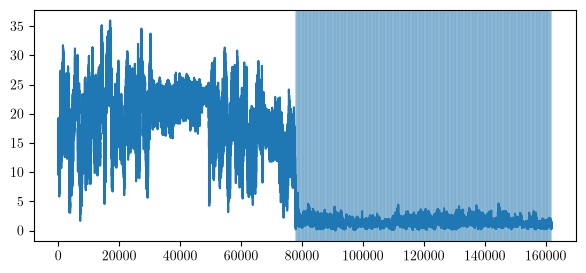

In [259]:
# idxs_valid = range(28)

# input: arrays of independent runs for a single phi
def local_conc_trace(all_concs, all_dists, cidx, ridx, thresh=4, closed=True):
    local_conc = np.array(all_concs[cidx][ridx])
    pattern_dist = np.array(all_dists[cidx][ridx])

    if closed:
        didx = np.where(pattern_dist < thresh)
    else:
        didx = np.where(pattern_dist >= thresh)

    return didx, local_conc[didx]

def local_conc_avg(local_concentration, pattern_distances, conc_idxs, run_idxs):
    """run_idxs: one run list for every concentration, or one row per concentration
    (a run-level bootstrap draw)."""
    phi_local_open = np.zeros(len(conc_idxs))
    phi_local_closed = np.zeros(len(conc_idxs))

    for i, cidx in enumerate(conc_idxs):
        _local_conc_closed_all_runs = []
        _local_conc_open_all_runs = []

        for run in (run_idxs[i] if np.ndim(run_idxs) > 1 else run_idxs):
            ic, lcc = local_conc_trace(
                local_concentration, 
                pattern_distances, 
                cidx, run, closed=True
            )
            io, lco = local_conc_trace(
                local_concentration, 
                pattern_distances, 
                cidx, run, closed=False
            )
            _local_conc_closed_all_runs = np.concatenate(
                (_local_conc_closed_all_runs, lcc)
            )
            _local_conc_open_all_runs = np.concatenate(
                (_local_conc_open_all_runs, lco)
            )

        # a run-level draw can miss every closed (or open) frame at this concentration
        phi_local_closed[i] = np.mean(_local_conc_closed_all_runs) if len(_local_conc_closed_all_runs) else np.nan
        phi_local_open[i] = np.mean(_local_conc_open_all_runs) if len(_local_conc_open_all_runs) else np.nan

    return phi_local_closed, phi_local_open

fig, ax = plt.subplots(1,1,figsize=(7, 3))

run = 4
cidx = 9
didx, local_conc = local_conc_trace(
    local_concentration, 
    pattern_distances, 
    cidx, run)
ax.plot(pattern_distances[cidx][run])

# ax2 = ax.twinx()
# ax2.scatter(didx[0], local_conc, s=5, color="red")

for k in didx[0]:
    if k % 100 == 0:
        ax.axvline(k, alpha=0.1)

In [203]:
np.random.choice([1,2,3], 3)

array([3, 1, 3])

In [376]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on each fixed log-time grid
smooth_sigma = 30      # CDF smoothing width in grid bins (was 50: over-smooths here)
# ---------------------------------------------------------------------------

conc_valid = np.array(concentrations)[idxs_valid]          # == phi_infs[:-2], uniform spacing
K         = len(conc_valid)

# pooled series per concentration, in SECONDS.  escape = closed/bound dwell
# (contact -> x_div), return = open/unbound dwell (x_div -> contact).
series_b = [np.concatenate(bound_times[k]) for k in idxs_valid]
series_u = [np.concatenate(unbound_times[k]) for k in idxs_valid]

N_SUB, NBOOT, LOGFIT = 6, 100, True          # N_SUB must match fit_c/fit_o
K_BATCH  = 7
# assert K_BATCH <= min(s.shape[0] for s in series_b + series_u), "more batches than sojourns"

theta = 40 * 1e3 / (6e23 * (25 * 1e-9)**3)
conc_valid_muM = np.array(conc_valid) * theta

lams_phi = np.logspace(-10, 1, 23)          # smoothing range for the phi-direction fit
tr  = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0**z) if LOGFIT else (lambda z: z)

def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size; n = (N - 1)*n_sub + 1
    t = np.linspace(0.0, 1.0, n); h = t[1] - t[0]
    idx = np.arange(N)*n_sub
    E2 = (np.eye(n, k=1)*-2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n)); S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None]*S)/w.sum() + lam*h*(E2.T @ E2)/h**4
    A += 1e-12*np.trace(A)/n*np.eye(n)
    H = np.linalg.solve(A, S.T*w/w.sum())          # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so the nan endpoints can't leak
    return dict(x=x[0] + (x[-1] - x[0])*t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0])/(n - 1)) & (t <= (idx[w > 0][-1])/(n - 1)))

def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = (f["y"][f["idx"]] - np.where(m, d, 0.0))/(1.0 - np.diag(f["H"][f["idx"]]))
        out.append((np.mean(e[m]**2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out]); k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

def phi_spline(F):
    """Cubic smoothing spline through F(phi), fitted in log10 space at the LOOCV lambda."""
    w = (np.isfinite(F) & (F > 0)).astype(float)
    d = tr(np.where(w > 0, F, 1.0))
    lam, _, _ = loocv_smooth(conc_valid_muM, d, w, lams_phi)
    f = fit_smooth(conc_valid_muM, d, w, lam)
    return np.where(w > 0, inv(f["y"][f["idx"]]), np.nan), lam, f["edf"]

def make_grid(all_series, n=n_grid):
    """One fixed log-time grid shared by every concentration (so PDFs line up)."""
    lo = min(a[a > 0].min() for a in all_series)
    hi = max(a.max()        for a in all_series)
    return np.logspace(np.log10(lo), np.log10(hi), n)

def pdf_on_grid(times, grid, sigma=smooth_sigma):
    """Smoothed empirical pdf f(t) evaluated on the *fixed* grid."""
    t = np.sort(np.asarray(times, float)); t = t[t > 0]
    u = np.log10(grid)
    F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid
    F = gaussian_filter1d(F, sigma=sigma, mode='nearest')  # smooth the CDF
    pdf = np.gradient(F, u) / (grid * np.log(10.0))        # f(t) = dF/dt
    return np.clip(pdf, 0.0, None)

def score2_fisher(t, p_lo, p0, p_hi, dphi):
    """∫ P(t|phi) (∂logP/∂phi)² dt  — score-squared Fisher estimator (central 3-pt in phi)."""
    fl    = p0.max() * 1e-10
    lp_lo = np.log(np.maximum(p_lo, fl))
    lp_hi = np.log(np.maximum(p_hi, fl))
    score = (lp_hi - lp_lo) / (2.0 * dphi)                 # ∂logP/∂phi  (central)
    integrand = p0 * score**2                              # = (∂P/∂phi)² / P
    integrand = np.where((p0 > fl) & (p_lo > fl) & (p_hi > fl), integrand, 0.0)
    return np.trapezoid(integrand, t)                      # = +I(phi), always ≥ 0

# fixed log-time grids, shared by the full data and every bootstrap replicate
grid_b, grid_u = make_grid(series_b), make_grid(series_u)

def poly_fisher_rate(sb, su):
    """Polymer Fisher rate from the closed/open duration PDFs, one value per concentration.

    Same estimator as fisher_rate_rouse (viz-rouse): score from the OUTER pair
    (phi_k, phi_k+2) weighted by P(t|phi_k), prefactor phi_k^2, normalised by the cycle
    time <t_closed> + <t_open>.  conc_valid is not uniformly spaced here, so the stencil
    width is read off the grid at each k.  The last two entries are nan -- phi_k+2 is
    off the end of the sweep -- as is any concentration a run draw left with no sojourn.
    """
    nan_row = np.full(n_grid, np.nan)
    Pb = np.array([pdf_on_grid(s, grid_b) if s.size else nan_row for s in sb])
    Pu = np.array([pdf_on_grid(s, grid_u) if s.size else nan_row for s in su])
    tau = np.array([b.mean() + u.mean() if b.size and u.size else np.nan
                    for b, u in zip(sb, su)])
    F = np.full(K, np.nan)
    for k in range(K - 2):                      # last two: phi_k+2 is off the sweep
        dphi_k = (conc_valid_muM[k + 2] - conc_valid_muM[k]) / 2
        I_b = score2_fisher(grid_b, Pb[k], Pb[k], Pb[k + 2], dphi_k)
        I_u = score2_fisher(grid_u, Pu[k], Pu[k], Pu[k + 2], dphi_k)
        F[k] = conc_valid_muM[k]**2*(I_b + I_u)/tau[k]
    return F, tau

In [377]:
### full-data averages
# phi_local = np.array([np.mean(np.concatenate(local_concentration[k])) for k in idxs_valid])

phi_local_c, phi_local_o = local_conc_avg(
    local_concentration, 
    pattern_distances, 
    idxs_valid, 
    range(7)
)

tau_on = np.array([np.mean(np.concatenate(on_times[k])) for k in idxs_valid])
tau_off = np.array([np.mean(np.concatenate(off_times[k])) for k in idxs_valid])
tau_on_smooth, _, _ = phi_spline(tau_on)
tau_off_smooth, _, _ = phi_spline(tau_off)

tau_closed = np.array([np.mean(np.concatenate(bound_times[k])) for k in idxs_valid])
tau_open = np.array([np.mean(np.concatenate(unbound_times[k])) for k in idxs_valid])

tau_closed_smooth, _, _ = phi_spline(tau_closed)
tau_open_smooth, _, _ = phi_spline(tau_open)

phi_local_c_smooth, _, _ = phi_spline(phi_local_c)
phi_local_o_smooth, _, _ = phi_spline(phi_local_o)

p_closed = tau_closed/(tau_closed+tau_open)
p_open = tau_open/(tau_closed+tau_open)
phi_local = phi_local_c*p_closed+phi_local_o*p_open

K_D = 3
ku = 1 / np.mean(tau_on[0])   # divide by 180 so that tau_burst_free ranges from 4 to 17 mins
kb = ku / K_D
tau_burst_free = 1 / ku + 1 / (conc_valid_muM * kb)
tau_burst_o = 1 / ku + 1 / (phi_local_o * theta * kb)
tau_burst_c = 1 / ku + 1 / (phi_local_c * theta * kb)

# closed Fisher rate
dphi_local_c = np.gradient(phi_local_c_smooth, conc_valid)
phi_local_c_gain = (dphi_local_c * conc_valid / phi_local_c_smooth) ** 2
fisher_c = phi_local_c_gain / tau_burst_c

# open Fisher rate
dphi_local_o = np.gradient(phi_local_o_smooth, conc_valid)
phi_local_o_gain = (dphi_local_o * conc_valid / phi_local_o_smooth) ** 2
fisher_o = phi_local_o_gain / tau_burst_o

# local Fisher rate
fisher_local = fisher_c*p_closed + fisher_o*p_open
fisher_local_smooth, _, _ = phi_spline(fisher_local)
fisher_c_smooth, _, _ = phi_spline(fisher_c)
fisher_o_smooth, _, _ = phi_spline(fisher_o)

# polymer Fisher rate, from the closed/open duration PDFs
fisher_poly, tau_poly = poly_fisher_rate(series_b, series_u)
fisher_poly_smooth, _, _ = phi_spline(fisher_poly)


### batch averages for bootstrap
phi_local_c_batch = np.zeros((NBOOT, len(idxs_valid)))
phi_local_o_batch = np.zeros((NBOOT, len(idxs_valid)))
phi_local_c_var = np.zeros(len(idxs_valid))
phi_local_o_var = np.zeros(len(idxs_valid))

fisher_c_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_o_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_local_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_poly_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_c_var = np.zeros(len(idxs_valid))
fisher_o_var = np.zeros(len(idxs_valid))
fisher_local_var = np.zeros(len(idxs_valid))

for i in range(NBOOT):
    # run-level (cluster) bootstrap: resample whole runs, shared by phi and the dwell times
    runs_ = np.random.randint(0, 7, size=(len(idxs_valid), 7))

    phi_local_c_batch[i], phi_local_o_batch[i] = local_conc_avg(
        local_concentration, 
        pattern_distances, 
        idxs_valid, 
        runs_
    )

    tau_open_ = np.zeros(len(idxs_valid))
    tau_closed_ = np.zeros(len(idxs_valid))
    series_b_, series_u_ = [], []

    for ik, k in enumerate(idxs_valid):

        series_c_ = np.concatenate([bound_times[k][r] for r in runs_[ik]])
        series_o_ = np.concatenate([unbound_times[k][r] for r in runs_[ik]])
        series_b_.append(series_c_)
        series_u_.append(series_o_)
        
        tau_closed_[ik] = series_c_.mean() if series_c_.size else np.nan
        tau_open_[ik] = series_o_.mean() if series_o_.size else np.nan

    p_closed_ = tau_closed_/(tau_closed_+tau_open_)
    p_open_ = tau_open_/(tau_closed_+tau_open_)

    phi_local_c_smooth_, _, _ = phi_spline(phi_local_c_batch[i])
    phi_local_o_smooth_, _, _ = phi_spline(phi_local_o_batch[i])

    tau_burst_o_ = 1 / ku + 1 / (phi_local_o_batch[i] * theta * kb)
    tau_burst_c_ = 1 / ku + 1 / (phi_local_c_batch[i] * theta * kb)

    # closed Fisher rate
    dphi_local_c_ = np.gradient(phi_local_c_smooth_, conc_valid)
    phi_local_c_gain_ = (dphi_local_c_ * conc_valid / phi_local_c_smooth_) ** 2
    fisher_c_batch[i] = phi_local_c_gain_ / tau_burst_c_

    # open Fisher rate
    dphi_local_o_ = np.gradient(phi_local_o_smooth_, conc_valid)
    phi_local_o_gain_ = (dphi_local_o_ * conc_valid / phi_local_o_smooth_) ** 2
    fisher_o_batch[i] = phi_local_o_gain_ / tau_burst_o_

    # local Fisher rate
    fisher_local_batch[i] = fisher_c_batch[i]*p_closed_ + fisher_o_batch[i]*p_open_

    # polymer Fisher rate, off the same run draw
    fisher_poly_batch[i], _ = poly_fisher_rate(series_b_, series_u_)


/tmp/ipykernel_185217/3363813466.py:103: RuntimeWarning: divide by zero encountered in divide
  tau_burst_c_ = 1 / ku + 1 / (phi_local_c_batch[i] * theta * kb)


Text(0.5, 0, 'Concentration $c$ ($\\mu$M)')

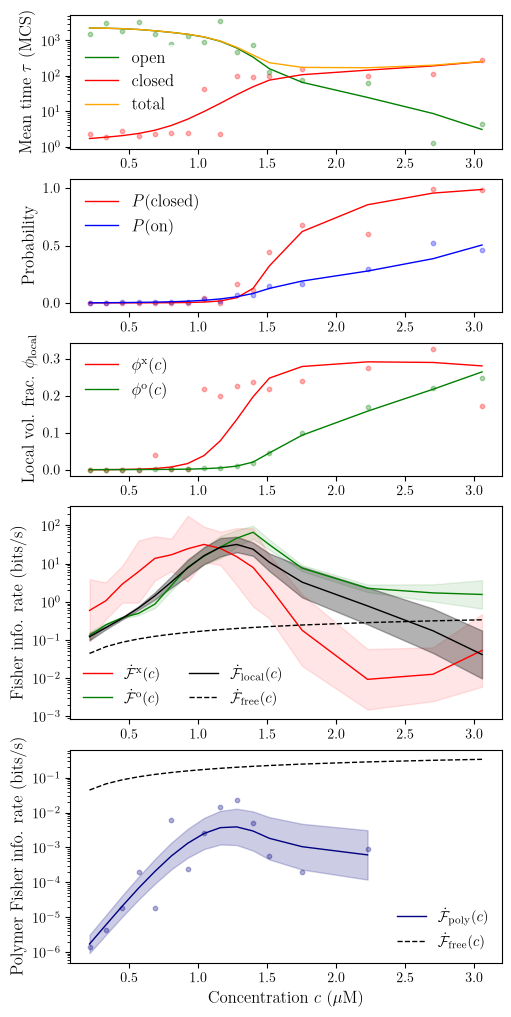

In [391]:
phi_local_c_var = np.nanvar(phi_local_c_batch, axis=0, ddof=1)
phi_local_o_var = np.nanvar(phi_local_o_batch, axis=0, ddof=1)

phi_local_c_var_smooth, _, _ = phi_spline(phi_local_c_var)
phi_local_o_var_smooth, _, _ = phi_spline(phi_local_o_var)

pos = lambda B: np.log10(np.where(B > 0, B, np.nan))   # drop replicates a run draw left undefined
log_fisher_c_var = np.nanvar(pos(fisher_c_batch), axis=0, ddof=1)
log_fisher_o_var = np.nanvar(pos(fisher_o_batch), axis=0, ddof=1)
log_fisher_local_var = np.nanvar(pos(fisher_local_batch), axis=0, ddof=1)
log_fisher_poly_var = np.full(K, np.nan)                    # last two: phi_k+2 off the sweep
log_fisher_poly_var[:K-2] = np.nanvar(pos(fisher_poly_batch[:, :K-2]), axis=0, ddof=1)

log_fisher_c_var_smooth, _, _ = phi_spline(log_fisher_c_var)
log_fisher_o_var_smooth, _, _ = phi_spline(log_fisher_o_var)
log_fisher_local_var_smooth, _, _ = phi_spline(log_fisher_local_var)
log_fisher_poly_var_smooth, _, _ = phi_spline(log_fisher_poly_var)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(5,1,figsize=(5, 10), 
                       gridspec_kw={"height_ratios": [1, 1, 1, 1.6,1.6]}, 
                       layout="constrained")

# ax[0].plot(conc_valid_muM, tau_on_smooth+tau_off_smooth, color="black", lw=1, label="burst")
# ax[0].plot(conc_valid_muM, tau_burst_free, color="black", lw=1, label="free")
ax[0].plot(conc_valid_muM, tau_open_smooth, color="green", lw=1, label="open")
ax[0].plot(conc_valid_muM, tau_closed_smooth, color="red", lw=1, label="closed")
ax[0].plot(conc_valid_muM, tau_closed_smooth+tau_open_smooth, color="orange", label="total", alpha=1, lw=1)
ax[0].scatter(conc_valid_muM, tau_closed, color="red", s=10, alpha=0.3)
ax[0].scatter(conc_valid_muM, tau_open, color="green", s=10, alpha=0.3)
ax[0].set_yscale('log')
ax[0].set_ylabel(r"Mean time $\tau$ (MCS)", fontsize=12)
ax[0].legend(fontsize=12, edgecolor="none", loc="center left")

ax[1].plot(conc_valid_muM, tau_closed_smooth/(tau_closed_smooth+tau_open_smooth), color="red", lw=1, label=r"$P(\rm closed)$")
ax[1].scatter(conc_valid_muM, tau_closed/(tau_closed+tau_open), color="red", s=10, alpha=0.3)
ax[1].plot(conc_valid_muM, tau_on_smooth/(tau_on_smooth+tau_off_smooth), color="blue", lw=1, label=r"$P(\rm on)$")
ax[1].scatter(conc_valid_muM, tau_on/(tau_on+tau_off), color="blue", s=10, alpha=0.3)
ax[1].set_ylabel(r"Probability", fontsize=12)
ax[1].legend(edgecolor="none", fontsize=12)
ax[1].set_ylim(-0.08, 1.08)

# ax[2].plot(conc_valid_muM, phi_local, color="black")
ax[2].plot(conc_valid_muM, phi_local_c_smooth, color="red", lw=1, label=r"$\phi^{\rm x}(c)$")
ax[2].plot(conc_valid_muM, phi_local_o_smooth, color="green", lw=1, label=r"$\phi^{\rm o}(c)$")
ax[2].scatter(conc_valid_muM, phi_local_c, color="red", s=10, alpha=0.3)
ax[2].scatter(conc_valid_muM, phi_local_o, color="green", s=10, alpha=0.3)
ax[2].set_ylabel(r"Local vol. frac. $\phi_{\rm local}$", fontsize=12)
ax[2].legend(fontsize=12, edgecolor="none")
# ax[2].fill_between(conc_valid_muM, phi_local_c_smooth - np.sqrt(phi_local_c_var),
#                    phi_local_c_smooth + np.sqrt(phi_local_c_var), color="red", alpha=0.2)
# ax[2].fill_between(conc_valid_muM, phi_local_o_smooth - np.sqrt(phi_local_o_var_smooth),
#                    phi_local_o_smooth + np.sqrt(phi_local_o_var_smooth), color="green", alpha=0.2)

ax[3].plot(conc_valid_muM, fisher_c_smooth, color="red", lw=1, label=r"$\dot{\mathcal{F}}^{\rm x}(c)$")
ax[3].plot(conc_valid_muM, fisher_o_smooth, color="green", lw=1, label=r"$\dot{\mathcal{F}}^{\rm o}(c)$")
ax[3].plot(conc_valid_muM, fisher_local_smooth, color="black", lw=1, label=r"$\dot{\mathcal{F}}_{\rm local}(c)$")
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_o_smooth)-np.sqrt(log_fisher_o_var_smooth)), 
                                   10**(np.log10(fisher_o_smooth)+np.sqrt(log_fisher_o_var_smooth)), 
                                   color="green", alpha=0.1)
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_c_smooth)-np.sqrt(log_fisher_c_var_smooth)), 
                                   10**(np.log10(fisher_c_smooth)+np.sqrt(log_fisher_c_var_smooth)), 
                                   color="red", alpha=0.1)
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_local_smooth)-np.sqrt(log_fisher_local_var_smooth)), 
                                   10**(np.log10(fisher_local_smooth)+np.sqrt(log_fisher_local_var_smooth)), 
                                   color="black",alpha=0.3)
ax[3].plot(conc_valid_muM, 1 / tau_burst_free, linestyle="dashed", lw=1, color="black", 
                                label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[3].set_ylabel(r"Fisher info. rate (bits/s)", fontsize=12)
ax[3].set_yscale('log')
ax[3].legend(fontsize=10.5, edgecolor="none", ncol=2)

ax[4].plot(conc_valid_muM, fisher_poly_smooth, color="navy", lw=1, label=r"$\dot{\mathcal{F}}_{\rm poly}(c)$")
ax[4].scatter(conc_valid_muM, fisher_poly, color="navy", s=10, alpha=0.3)
ax[4].fill_between(conc_valid_muM, 10**(np.log10(fisher_poly_smooth)-np.sqrt(log_fisher_poly_var_smooth)), 
                                   10**(np.log10(fisher_poly_smooth)+np.sqrt(log_fisher_poly_var_smooth)), 
                                   color="navy", alpha=0.2)
ax[4].plot(conc_valid_muM, 1 / tau_burst_free, linestyle="dashed", lw=1, color="black", 
                                label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[4].set_ylabel(r"Polymer Fisher info. rate (bits/s)", fontsize=12)
ax[4].set_yscale('log')
ax[4].legend(fontsize=10.5, edgecolor="none")
ax[4].set_xlabel("Concentration $c$ ($\mu$M)", fontsize=12)

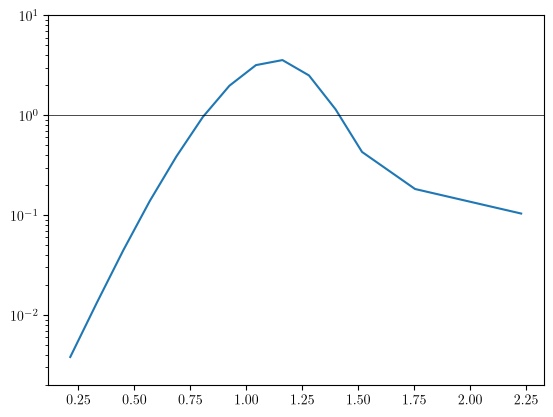

In [390]:
fig, ax = plt.subplots(1,1)

ax.set_ylim(2e-3, 10)
ax.plot(conc_valid_muM, fisher_poly_smooth * (tau_open_smooth+tau_closed_smooth))
ax.axhline(1, linestyle="solid", color="black", lw=0.5)
ax.set_yscale('log')

In [392]:
out_dir = "media/figures/20260908"
os.makedirs(out_dir, exist_ok=True) 
out_path = os.path.join(out_dir, "fisher_local_from_20260823.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260908/fisher_local_from_20260823.pdf
